# Air Quality Analysis and Machine Learning

## Project Overview

This notebook performs exploratory data analysis, visualization, statistical analysis, supervised machine learning, and unsupervised learning using British Columbia air quality data.

The analysis uses cleaned monitoring station and regional AQHI datasets prepared in the Data Ingestion and Cleaning notebook.

### Main Objectives

1. Explore air quality patterns and pollutant distributions.
2. Analyze relationships between pollutants and AQHI.
3. Develop regression models to estimate AQHI values.
4. Develop a Random Forest classification model to predict next-hour AQHI risk.
5. Evaluate model performance using appropriate metrics.
6. Explore pollutant patterns through K-Means clustering.

In [ ]:
# Install required libraries

!pip install pyspark matplotlib seaborn

In [ ]:

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("AirQualityAnalysis") \
    .getOrCreate()

print("Spark Version:", spark.version)


Spark Version: 4.0.5


In [ ]:
from pathlib import Path

# Define project and processed data directories
PROJECT_DIR = Path.cwd()
PROCESSED_DIR = PROJECT_DIR / "02_Processed_Data"

# Define Parquet dataset paths
station_path = PROCESSED_DIR / "station_data"
regional_path = PROCESSED_DIR / "regional_aqhi_data"

# Verify that both datasets exist
if not station_path.exists():
    raise FileNotFoundError(
        f"Monitoring station dataset not found: {station_path}"
    )

if not regional_path.exists():
    raise FileNotFoundError(
        f"Regional AQHI dataset not found: {regional_path}"
    )

# Load monitoring station data
station_df = spark.read.parquet(str(station_path))

# Load regional AQHI data
regional_df = spark.read.parquet(str(regional_path))

print("Datasets loaded successfully!")
print("Monitoring station records:", station_df.count())
print("Regional AQHI records:", regional_df.count())

Datasets loaded successfully!


In [ ]:

print("MONITORING STATION DATA")
print("Total Records:", station_df.count())
station_df.printSchema()
station_df.show(5, truncate=False)

print("\nREGIONAL AQHI DATA")
print("Total Records:", regional_df.count())
regional_df.printSchema()
regional_df.show(5, truncate=False)


MONITORING STATION DATA
Total Records: 15372
root
 |-- date_pst: timestamp (nullable = true)
 |-- aqhi_area: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_name_full: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- cgndb: string (nullable = true)
 |-- no2_rounded: double (nullable = true)
 |-- no2_rounded_3hr: double (nullable = true)
 |-- o3_rounded: double (nullable = true)
 |-- o3_rounded_3hr: double (nullable = true)
 |-- pm25_rounded: double (nullable = true)
 |-- pm25_rounded_3hr: double (nullable = true)
 |-- so2_rounded: double (nullable = true)
 |-- so2_rounded_3hr: double (nullable = true)
 |-- active: string (nullable = true)
 |-- aqhi_pm25: string (nullable = true)
 |-- aqhi_so2: string (nullable = true)
 |-- aqhi_classic: double (nullable = true)
 |-- aqhi_plus_pm25: integer (nullable = true)
 |-- aqhi_value: double (nullable = true)
 |-- msg_index: integer (nullable = true)
 

## 2. Exploratory Data Analysis

### 2.1 Dataset Overview

This section examines the structure, size, coverage, and quality of the monitoring station and regional AQHI datasets.

In [ ]:

# Import required functions
from pyspark.sql import functions as F

# 1. Dataset dimensions
print("MONITORING STATION DATA")
print("Rows:", station_df.count())
print("Columns:", len(station_df.columns))

print("\nREGIONAL AQHI DATA")
print("Rows:", regional_df.count())
print("Columns:", len(regional_df.columns))


# 2. Number of unique monitoring stations
print("\nUNIQUE MONITORING STATIONS:")
print(station_df.select("station_name").distinct().count())


# 3. Number of unique AQHI regions
print("\nUNIQUE AQHI REGIONS:")
print(regional_df.select("aqhi_area").distinct().count())


# 4. Date range of monitoring station data
print("\nMONITORING STATION DATE RANGE:")
station_df.select(
    F.min("date_pst").alias("Earliest Date"),
    F.max("date_pst").alias("Latest Date")
).show(truncate=False)


# 5. Date range of regional AQHI data
print("\nREGIONAL AQHI DATE RANGE:")
regional_df.select(
    F.min("date_pst").alias("Earliest Date"),
    F.max("date_pst").alias("Latest Date")
).show(truncate=False)


MONITORING STATION DATA
Rows: 15372
Columns: 38

REGIONAL AQHI DATA
Rows: 1122
Columns: 38

UNIQUE MONITORING STATIONS:
23

UNIQUE AQHI REGIONS:
6

MONITORING STATION DATE RANGE:
+-------------------+-------------------+
|Earliest Date      |Latest Date        |
+-------------------+-------------------+
|2026-10-06 01:00:00|2026-11-05 12:00:00|
+-------------------+-------------------+


REGIONAL AQHI DATE RANGE:
+-------------------+-------------------+
|Earliest Date      |Latest Date        |
+-------------------+-------------------+
|2026-10-28 17:00:00|2026-11-05 11:00:00|
+-------------------+-------------------+



### 2.2 Missing Values Analysis

This section identifies missing values in the monitoring station and regional AQHI datasets. It calculates the number and percentage of missing values in each column to assess data completeness.

In [ ]:

from pyspark.sql import functions as F

# Function to calculate missing values
def missing_value_analysis(df, dataset_name):

    total_rows = df.count()

    missing_counts = df.select([
        F.count(
            F.when(F.col(c).isNull(), c)
        ).alias(c)
        for c in df.columns
    ])

    print(f"\n{dataset_name} - Missing Values")

    results = []

    for column in df.columns:
        missing = missing_counts.collect()[0][column]

        if missing > 0:
            percentage = (missing / total_rows) * 100
            results.append((column, missing, round(percentage, 2)))

    result_df = spark.createDataFrame(
        results,
        ["Column", "Missing_Count", "Missing_Percentage"]
    )

    result_df.orderBy(
        F.desc("Missing_Percentage")
    ).show(50, truncate=False)


# Analyze both datasets
missing_value_analysis(
    station_df,
    "MONITORING STATION DATA"
)

missing_value_analysis(
    regional_df,
    "REGIONAL AQHI DATA"
)



MONITORING STATION DATA - Missing Values
+--------------------+-------------+------------------+
|Column              |Missing_Count|Missing_Percentage|
+--------------------+-------------+------------------+
|aqhi_plus_pm25_value|15372        |100.0             |
|so2_rounded         |8441         |54.91             |
|so2_rounded_3hr     |8190         |53.28             |
|o3_rounded          |956          |6.22              |
|no2_rounded         |832          |5.41              |
|aqhi_classic        |678          |4.41              |
|o3_rounded_3hr      |404          |2.63              |
|no2_rounded_3hr     |262          |1.7               |
|pm25_rounded_3hr    |169          |1.1               |
|aqhi_plus_pm25      |168          |1.09              |
|pm25_rounded        |168          |1.09              |
|aqhi_value          |136          |0.88              |
|msg_index           |136          |0.88              |
|aqhi_type           |136          |0.88              |
|aqhi_

### 2.3 Identifying Negative Pollutant Readings

This section investigates negative pollutant measurements in the monitoring station dataset. It examines the number and percentage of negative readings, reviews the data-quality flags created during data cleaning, and checks the minimum and maximum pollutant values.

In [ ]:

from pyspark.sql import functions as F

# Pollutant columns to investigate
pollutants = [
    "no2_rounded",
    "no2_rounded_3hr",
    "o3_rounded",
    "o3_rounded_3hr",
    "pm25_rounded",
    "pm25_rounded_3hr",
    "so2_rounded",
    "so2_rounded_3hr"
]

# Analyze negative readings
print("NEGATIVE POLLUTANT READINGS")

for column in pollutants:

    negative_count = station_df.filter(
        F.col(column) < 0
    ).count()

    total_count = station_df.filter(
        F.col(column).isNotNull()
    ).count()

    percentage = (
        negative_count / total_count * 100
        if total_count > 0 else 0
    )

    print(
        f"{column}: {negative_count} negative readings "
        f"({percentage:.2f}%)"
    )


# Check negative-reading flags
print("\nNEGATIVE READING FLAGS")

flag_columns = [
    "no2_rounded_negative_flag",
    "o3_rounded_negative_flag",
    "pm25_rounded_negative_flag",
    "so2_rounded_negative_flag",
    "has_negative_reading"
]

station_df.groupBy().agg(
    *[
        F.sum(F.col(c)).alias(c)
        for c in flag_columns
    ]
).show(truncate=False)


# Check minimum and maximum pollutant values
print("\nPOLLUTANT VALUE RANGES")

station_df.select(
    *[
        F.min(c).alias(c + "_min")
        for c in pollutants
    ],
    *[
        F.max(c).alias(c + "_max")
        for c in pollutants
    ]
).show(truncate=False)


NEGATIVE POLLUTANT READINGS
no2_rounded: 964 negative readings (6.63%)
no2_rounded_3hr: 929 negative readings (6.15%)
o3_rounded: 7 negative readings (0.05%)
o3_rounded_3hr: 1 negative readings (0.01%)
pm25_rounded: 0 negative readings (0.00%)
pm25_rounded_3hr: 0 negative readings (0.00%)
so2_rounded: 543 negative readings (7.83%)
so2_rounded_3hr: 549 negative readings (7.64%)

NEGATIVE READING FLAGS
+-------------------------+------------------------+--------------------------+-------------------------+--------------------+
|no2_rounded_negative_flag|o3_rounded_negative_flag|pm25_rounded_negative_flag|so2_rounded_negative_flag|has_negative_reading|
+-------------------------+------------------------+--------------------------+-------------------------+--------------------+
|964                      |7                       |0                         |543                      |1593                |
+-------------------------+------------------------+--------------------------+---------

### 2.4 AQHI Levels and Pollutant Distributions

This section examines AQHI statistics, risk category distribution, and pollutant concentration patterns. It uses descriptive statistics to understand the overall air quality conditions represented in the dataset.

In [ ]:

from pyspark.sql import functions as F

# 1. AQHI statistical summary
print("AQHI STATISTICS")

station_df.select(
    F.count("aqhi_value").alias("Total_Readings"),
    F.round(F.avg("aqhi_value"), 2).alias("Average_AQHI"),
    F.round(F.min("aqhi_value"), 2).alias("Minimum_AQHI"),
    F.round(F.max("aqhi_value"), 2).alias("Maximum_AQHI"),
    F.round(F.stddev("aqhi_value"), 2).alias("AQHI_Std_Dev")
).show()


# 2. AQHI risk category distribution
print("AQHI RISK CATEGORY DISTRIBUTION")

station_df.groupBy("label_text").count() \
    .orderBy(F.desc("count")) \
    .show(truncate=False)


# 3. Pollutant statistics
print("POLLUTANT STATISTICS")

station_df.select(
    *[
        F.round(F.avg(c), 2).alias(c + "_avg")
        for c in [
            "no2_rounded",
            "o3_rounded",
            "pm25_rounded",
            "so2_rounded"
        ]
    ],
    *[
        F.round(F.max(c), 2).alias(c + "_max")
        for c in [
            "no2_rounded",
            "o3_rounded",
            "pm25_rounded",
            "so2_rounded"
        ]
    ]
).show(truncate=False)


# 4. AQHI value distribution
print("AQHI VALUE DISTRIBUTION")

station_df.groupBy("aqhi_value") \
    .count() \
    .orderBy("aqhi_value") \
    .show(30, truncate=False)


AQHI STATISTICS
+--------------+------------+------------+------------+------------+
|Total_Readings|Average_AQHI|Minimum_AQHI|Maximum_AQHI|AQHI_Std_Dev|
+--------------+------------+------------+------------+------------+
|         15236|        1.52|         1.0|         8.0|        0.64|
+--------------+------------+------------+------------+------------+

AQHI RISK CATEGORY DISTRIBUTION
+-------------+-----+
|label_text   |count|
+-------------+-----+
|Low Risk     |15076|
|Moderate Risk|155  |
|NULL         |136  |
|High Risk    |5    |
+-------------+-----+

POLLUTANT STATISTICS
+---------------+--------------+----------------+---------------+---------------+--------------+----------------+---------------+
|no2_rounded_avg|o3_rounded_avg|pm25_rounded_avg|so2_rounded_avg|no2_rounded_max|o3_rounded_max|pm25_rounded_max|so2_rounded_max|
+---------------+--------------+----------------+---------------+---------------+--------------+----------------+---------------+
|4.63           |1

## 3. Data Visualization

This section presents visual representations of AQHI risk categories, average pollutant concentrations, and air quality trends over time. These visualizations help identify patterns and communicate the findings from the exploratory data analysis.

In [ ]:

!pip install matplotlib seaborn

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pyspark.sql import functions as F

sns.set_theme(style="whitegrid")


### 3.1 AQHI Risk Category Distribution

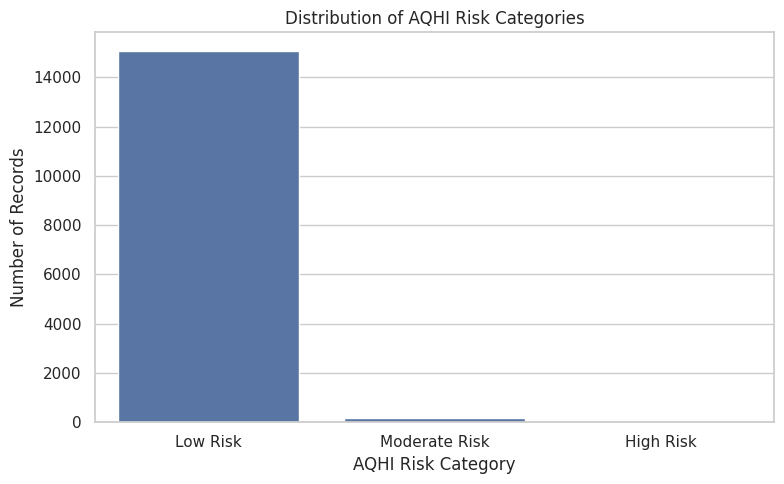

In [ ]:

risk_df = station_df.filter(
    F.col("label_text").isNotNull()
).groupBy("label_text").count().toPandas()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=risk_df,
    x="label_text",
    y="count"
)

plt.title("Distribution of AQHI Risk Categories")
plt.xlabel("AQHI Risk Category")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


### 3.2 Average Pollutant Concentrations

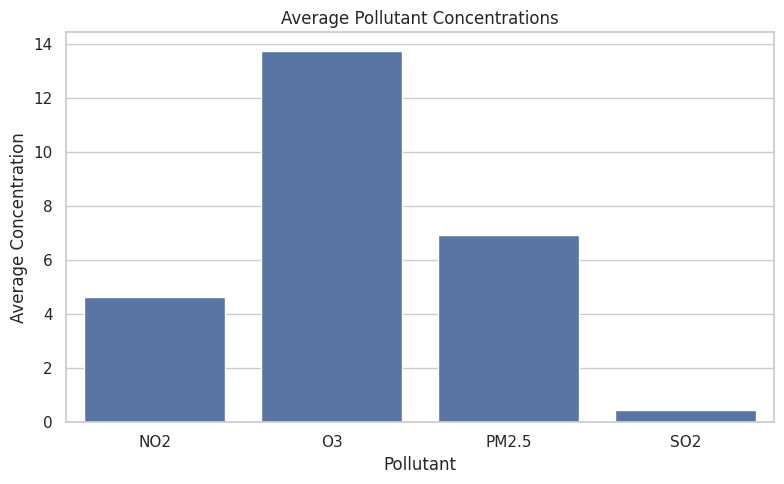

In [ ]:

pollutants = [
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "so2_rounded"
]

pollutant_avg = station_df.select(
    *[
        F.avg(c).alias(c)
        for c in pollutants
    ]
).toPandas()

pollutant_avg = pollutant_avg.T.reset_index()
pollutant_avg.columns = ["Pollutant", "Average"]

pollutant_avg["Pollutant"] = [
    "NO2", "O3", "PM2.5", "SO2"
]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=pollutant_avg,
    x="Pollutant",
    y="Average"
)

plt.title("Average Pollutant Concentrations")
plt.xlabel("Pollutant")
plt.ylabel("Average Concentration")
plt.tight_layout()
plt.show()


### 3.3 AQHI Trends Over Time

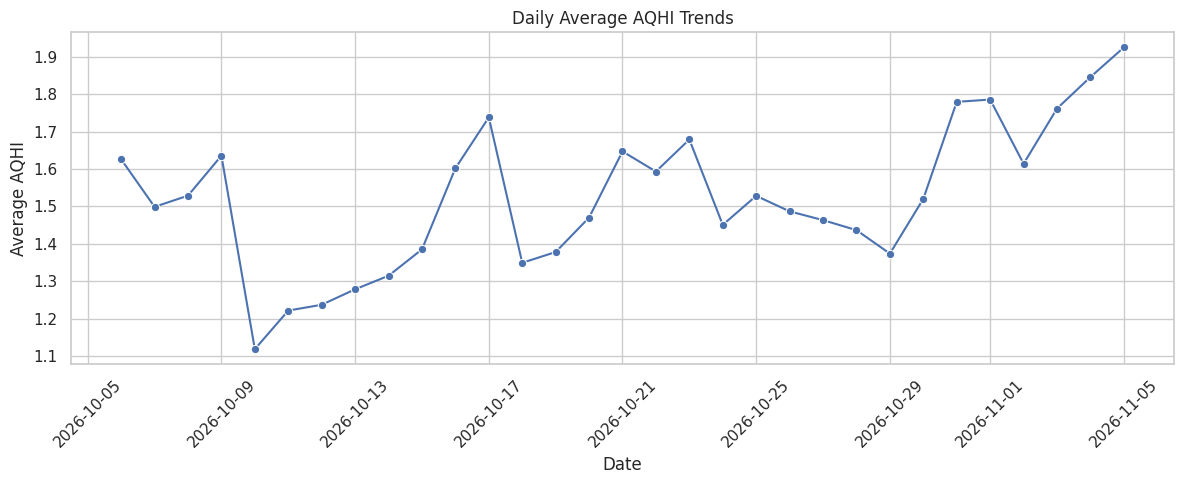

In [ ]:

daily_aqhi = station_df.filter(
    F.col("aqhi_value").isNotNull()
).groupBy(
    F.to_date("date_pst").alias("date")
).agg(
    F.avg("aqhi_value").alias("average_aqhi")
).orderBy("date")

daily_aqhi_pd = daily_aqhi.toPandas()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=daily_aqhi_pd,
    x="date",
    y="average_aqhi",
    marker="o"
)

plt.title("Daily Average AQHI Trends")
plt.xlabel("Date")
plt.ylabel("Average AQHI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 3.4 Correlation Analysis Between Pollutants and AQHI

This section examines the relationship between individual pollutant concentrations and AQHI values using Pearson correlation coefficients.

In [ ]:

from pyspark.sql import functions as F

pollutants = [
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "so2_rounded"
]

print("CORRELATION BETWEEN POLLUTANTS AND AQHI")
print("-----------------------------------------")

for pollutant in pollutants:

    valid_data = station_df.filter(
        (F.col(pollutant).isNotNull()) &
        (F.col(pollutant) >= 0) &
        (F.col("aqhi_value").isNotNull())
    )

    correlation = valid_data.stat.corr(
        pollutant,
        "aqhi_value"
    )

    record_count = valid_data.count()

    print(
        f"{pollutant} vs AQHI: "
        f"{correlation:.4f} "
        f"(Records: {record_count})"
    )


CORRELATION BETWEEN POLLUTANTS AND AQHI
-----------------------------------------
no2_rounded vs AQHI: 0.3013 (Records: 13495)
o3_rounded vs AQHI: 0.0971 (Records: 14319)
pm25_rounded vs AQHI: 0.7404 (Records: 15204)
so2_rounded vs AQHI: 0.1685 (Records: 6341)


### 3.5 Pollutant Correlation Heatmap

This section visualizes the pairwise correlations between the four pollutants and AQHI using a correlation heatmap.

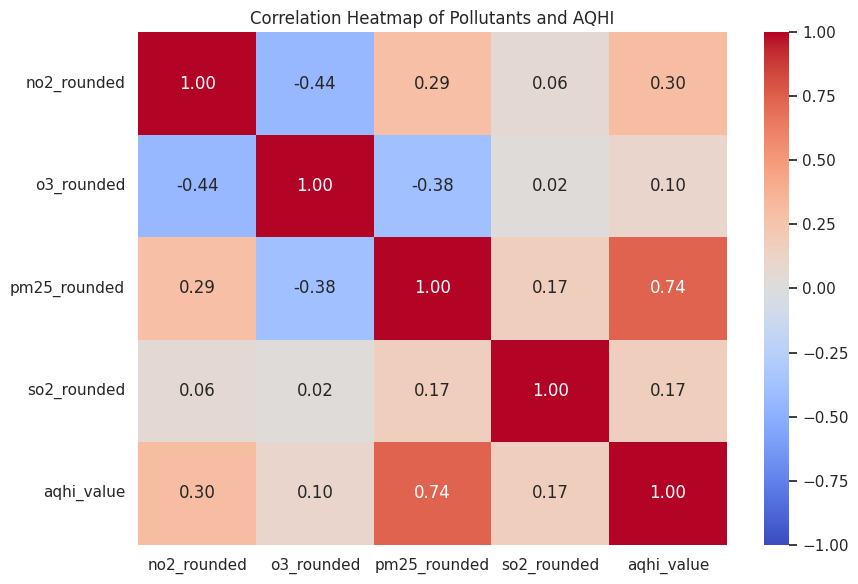

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Select pollutant and AQHI columns
correlation_columns = [
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "so2_rounded",
    "aqhi_value"
]

# Calculate pairwise correlations
correlation_matrix = pd.DataFrame(
    index=correlation_columns,
    columns=correlation_columns,
    dtype=float
)

for col1 in correlation_columns:
    for col2 in correlation_columns:

        valid_data = station_df.filter(
            F.col(col1).isNotNull() &
            F.col(col2).isNotNull() &
            (F.col(col1) >= 0) &
            (F.col(col2) >= 0)
        )

        correlation_matrix.loc[col1, col2] = (
            valid_data.stat.corr(col1, col2)
        )

# Plot heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix.astype(float),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Pollutants and AQHI")
plt.tight_layout()
plt.show()


## 4. Supervised Learning – AQHI Regression

### 4.1 Feature Selection and Dataset Preparation

The selected input features are NO2, O3, and PM2.5 concentrations. The target variable is AQHI (`aqhi_value`). Negative pollutant readings are treated as missing values, and records with missing input features or target values are excluded from the modelling dataset.

In [ ]:

from pyspark.sql import functions as F

# Select required columns
model_df = station_df.select(
    "date_pst",
    "station_name",
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "aqhi_value"
)

# Convert negative pollutant readings to NULL
pollutants = [
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded"
]

for column in pollutants:
    model_df = model_df.withColumn(
        column,
        F.when(F.col(column) < 0, None)
         .otherwise(F.col(column))
    )

# Remove records with missing target or input features
model_df = model_df.dropna(
    subset=[
        "no2_rounded",
        "o3_rounded",
        "pm25_rounded",
        "aqhi_value"
    ]
)

print("Supervised Learning Dataset Prepared")

print("Total usable records:", model_df.count())

print("\nDataset Schema:")
model_df.printSchema()

print("\nSample Records:")
model_df.show(10, truncate=False)


Supervised Learning Dataset Prepared
Total usable records: 13148

Dataset Schema:
root
 |-- date_pst: timestamp (nullable = true)
 |-- station_name: string (nullable = true)
 |-- no2_rounded: double (nullable = true)
 |-- o3_rounded: double (nullable = true)
 |-- pm25_rounded: double (nullable = true)
 |-- aqhi_value: double (nullable = true)


Sample Records:
+-------------------+--------------------------------+-----------+----------+------------+----------+
|date_pst           |station_name                    |no2_rounded|o3_rounded|pm25_rounded|aqhi_value|
+-------------------+--------------------------------+-----------+----------+------------+----------+
|2026-10-15 16:00:00|Kamloops Federal Building       |7.0        |20.2      |4.3         |1.0       |
|2026-10-19 08:00:00|Kamloops Federal Building       |18.2       |1.2       |6.5         |1.76      |
|2026-11-05 00:00:00|Kamloops Federal Building       |7.1        |11.3      |23.9        |3.0       |
|2026-10-26 08:00:00|Kelo

In [ ]:

print("FINAL DATASET SUMMARY")

print("Total Records:", model_df.count())

print(
    "Unique Stations:",
    model_df.select("station_name").distinct().count()
)

print("\nMissing Values:")

model_df.select([
    F.count(
        F.when(F.col(c).isNull(), c)
    ).alias(c)
    for c in model_df.columns
]).show()


FINAL DATASET SUMMARY
Total Records: 13148
Unique Stations: 23

Missing Values:
+--------+------------+-----------+----------+------------+----------+
|date_pst|station_name|no2_rounded|o3_rounded|pm25_rounded|aqhi_value|
+--------+------------+-----------+----------+------------+----------+
|       0|           0|          0|         0|           0|         0|
+--------+------------+-----------+----------+------------+----------+



### 4.2 Splitting the Dataset into Training and Testing Sets

The prepared dataset is divided into training and testing subsets using an 80:20 ratio. The training dataset is used to build the regression models, while the testing dataset is used to evaluate their performance on unseen observations.

In [ ]:

# Split the dataset into training and testing sets

train_df, test_df = model_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

# Display dataset sizes
print("TRAINING AND TESTING DATA SPLIT")

print("Total Records:", model_df.count())

print("Training Records:", train_df.count())

print("Testing Records:", test_df.count())

# Calculate percentages
total = model_df.count()

print(
    "Training Percentage:",
    round(train_df.count() / total * 100, 2), "%"
)

print(
    "Testing Percentage:",
    round(test_df.count() / total * 100, 2), "%"
)


TRAINING AND TESTING DATA SPLIT
Total Records: 13148
Training Records: 10576
Testing Records: 2572
Training Percentage: 80.44 %
Testing Percentage: 19.56 %


### 4.3 Linear Regression Model

In [ ]:

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression

from pyspark.ml.evaluation import RegressionEvaluator


In [ ]:

# Define input features
feature_columns = [
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded"
]

# Combine features into a vector
assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

# Transform training and testing datasets
train_data = assembler.transform(train_df)
test_data = assembler.transform(test_df)

print("Feature vector created successfully!")

train_data.select(
    "features",
    "aqhi_value"
).show(5, truncate=False)


Feature vector created successfully!
+--------------+----------+
|features      |aqhi_value|
+--------------+----------+
|[5.9,0.3,9.7] |1.0       |
|[1.7,7.1,2.6] |1.0       |
|[3.0,25.8,7.2]|1.0       |
|[3.2,1.1,7.6] |1.0       |
|[1.0,34.5,1.3]|1.0       |
+--------------+----------+
only showing top 5 rows


In [ ]:

# Initialize Linear Regression
lr = LinearRegression(
    featuresCol="features",
    labelCol="aqhi_value",
    maxIter=100,
    regParam=0.0
)

# Train the model
lr_model = lr.fit(train_data)

print("Linear Regression Model Trained Successfully!")

print("Coefficients:", lr_model.coefficients)
print("Intercept:", lr_model.intercept)


Linear Regression Model Trained Successfully!
Coefficients: [0.04652738174697461,0.03744637678691303,0.08727978970141487]
Intercept: 0.1929275904035918


In [ ]:

# Generate predictions on testing data
predictions = lr_model.transform(test_data)

print("MODEL PREDICTIONS")

predictions.select(
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "aqhi_value",
    "prediction"
).show(15, truncate=False)


MODEL PREDICTIONS
+-----------+----------+------------+----------+------------------+
|no2_rounded|o3_rounded|pm25_rounded|aqhi_value|prediction        |
+-----------+----------+------------+----------+------------------+
|4.7        |2.7       |4.7         |1.0       |0.9229265135356877|
|1.7        |32.6      |1.8         |1.0       |1.6498796440893602|
|0.6        |34.0      |7.0         |1.0       |2.1049793581167235|
|6.0        |30.0      |4.8         |1.0       |2.0144261750596217|
|5.3        |7.7       |3.0         |1.0       |0.9896991840260323|
|3.4        |24.3      |7.1         |1.91      |1.8807541511453376|
|3.6        |12.4      |4.1         |1.0       |1.1826083746262228|
|5.2        |17.5      |6.3         |1.98      |1.6400442443777514|
|1.2        |24.4      |2.2         |1.54      |1.354467579443752 |
|0.5        |31.4      |6.0         |2.02      |1.9156862505946375|
|4.3        |9.9       |4.4         |1.0       |1.1477455367922471|
|6.1        |7.8       |4.6   

### 4.4 Linear Regression Model Evaluation

In [ ]:

from pyspark.ml.evaluation import RegressionEvaluator

# RMSE evaluation
rmse_evaluator = RegressionEvaluator(
    labelCol="aqhi_value",
    predictionCol="prediction",
    metricName="rmse"
)

rmse = rmse_evaluator.evaluate(predictions)


# MAE evaluation
mae_evaluator = RegressionEvaluator(
    labelCol="aqhi_value",
    predictionCol="prediction",
    metricName="mae"
)

mae = mae_evaluator.evaluate(predictions)


# R2 evaluation
r2_evaluator = RegressionEvaluator(
    labelCol="aqhi_value",
    predictionCol="prediction",
    metricName="r2"
)

r2 = r2_evaluator.evaluate(predictions)


# Display results
print("LINEAR REGRESSION MODEL PERFORMANCE")
print("-----------------------------------")

print("RMSE:", round(rmse, 4))
print("MAE:", round(mae, 4))
print("R2 Score:", round(r2, 4))


LINEAR REGRESSION MODEL PERFORMANCE
-----------------------------------
RMSE: 0.2929
MAE: 0.238
R2 Score: 0.8035


### 4.5 Random Forest Regression Model

In [ ]:

from pyspark.ml.regression import RandomForestRegressor

# Initialize Random Forest Regression
rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="aqhi_value",
    numTrees=100,
    maxDepth=8,
    seed=42
)

print("Random Forest Regressor initialized successfully!")


Random Forest Regressor initialized successfully!


In [ ]:

# Train the Random Forest model
rf_model = rf.fit(train_data)

print("Random Forest Model Trained Successfully!")

# Display feature importance
print("\nFEATURE IMPORTANCE")

for feature, importance in zip(
    feature_columns,
    rf_model.featureImportances
):
    print(feature, ":", round(float(importance), 4))


Random Forest Model Trained Successfully!

FEATURE IMPORTANCE
no2_rounded : 0.1346
o3_rounded : 0.2009
pm25_rounded : 0.6645


In [ ]:

# Generate predictions on testing dataset
rf_predictions = rf_model.transform(test_data)

print("RANDOM FOREST PREDICTIONS")

rf_predictions.select(
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "aqhi_value",
    "prediction"
).show(15, truncate=False)


RANDOM FOREST PREDICTIONS
+-----------+----------+------------+----------+------------------+
|no2_rounded|o3_rounded|pm25_rounded|aqhi_value|prediction        |
+-----------+----------+------------+----------+------------------+
|4.7        |2.7       |4.7         |1.0       |1.1056342397966612|
|1.7        |32.6      |1.8         |1.0       |1.8490337667834624|
|0.6        |34.0      |7.0         |1.0       |2.1348423005743795|
|6.0        |30.0      |4.8         |1.0       |2.056631981410459 |
|5.3        |7.7       |3.0         |1.0       |1.089280018990188 |
|3.4        |24.3      |7.1         |1.91      |1.6346622691045107|
|3.6        |12.4      |4.1         |1.0       |1.0867844279508108|
|5.2        |17.5      |6.3         |1.98      |1.5024069185850955|
|1.2        |24.4      |2.2         |1.54      |1.223290033456091 |
|0.5        |31.4      |6.0         |2.02      |1.9467620813334718|
|4.3        |9.9       |4.4         |1.0       |1.097158270445453 |
|6.1        |7.8      

### 4.6 Random Forest Regression Model Evaluation

In [ ]:

from pyspark.ml.evaluation import RegressionEvaluator

# RMSE
rf_rmse = RegressionEvaluator(
    labelCol="aqhi_value",
    predictionCol="prediction",
    metricName="rmse"
).evaluate(rf_predictions)

# MAE
rf_mae = RegressionEvaluator(
    labelCol="aqhi_value",
    predictionCol="prediction",
    metricName="mae"
).evaluate(rf_predictions)

# R2
rf_r2 = RegressionEvaluator(
    labelCol="aqhi_value",
    predictionCol="prediction",
    metricName="r2"
).evaluate(rf_predictions)


print("RANDOM FOREST MODEL PERFORMANCE")
print("--------------------------------")

print("RMSE:", round(rf_rmse, 4))
print("MAE:", round(rf_mae, 4))
print("R2 Score:", round(rf_r2, 4))


RANDOM FOREST MODEL PERFORMANCE
--------------------------------
RMSE: 0.2879
MAE: 0.1786
R2 Score: 0.8102


## 5. Next-Hour AQHI Risk Classification

### 5.1 Examining Timestamp Continuity and AQHI Categories

In [ ]:

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Examine timestamp format
print("TIMESTAMP DATA TYPE")
station_df.printSchema()

# Check available AQHI risk categories
print("\nAQHI RISK CATEGORIES")

station_df.groupBy("label_text").count().show()

# Check sample timestamps
print("\nSAMPLE TIMESTAMPS")

station_df.select(
    "date_pst",
    "station_name",
    "aqhi_value",
    "label_text"
).orderBy("date_pst").show(15, truncate=False)

# Check whether timestamps are consecutive hourly observations
window = Window.partitionBy(
    "station_name"
).orderBy("date_pst")

time_check = station_df.withColumn(
    "next_timestamp",
    F.lead("date_pst").over(window)
).withColumn(
    "hour_difference",
    (
        F.col("next_timestamp").cast("long")
        - F.col("date_pst").cast("long")
    ) / 3600
)

print("\nTIME DIFFERENCE DISTRIBUTION")

time_check.groupBy(
    "hour_difference"
).count().orderBy("hour_difference").show(20)


TIMESTAMP DATA TYPE
root
 |-- date_pst: timestamp (nullable = true)
 |-- aqhi_area: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_name_full: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- cgndb: string (nullable = true)
 |-- no2_rounded: double (nullable = true)
 |-- no2_rounded_3hr: double (nullable = true)
 |-- o3_rounded: double (nullable = true)
 |-- o3_rounded_3hr: double (nullable = true)
 |-- pm25_rounded: double (nullable = true)
 |-- pm25_rounded_3hr: double (nullable = true)
 |-- so2_rounded: double (nullable = true)
 |-- so2_rounded_3hr: double (nullable = true)
 |-- active: string (nullable = true)
 |-- aqhi_pm25: string (nullable = true)
 |-- aqhi_so2: string (nullable = true)
 |-- aqhi_classic: double (nullable = true)
 |-- aqhi_plus_pm25: integer (nullable = true)
 |-- aqhi_value: double (nullable = true)
 |-- msg_index: integer (nullable = true)
 |-- aqhi_type: string (nu

### 5.2 Creating the Next-Hour AQHI Prediction Target

This section creates the target variable for predicting the next-hour AQHI risk category. Observations are arranged chronologically for each monitoring station, and the AQHI risk category from the next observation is assigned as the prediction target. Only consecutive observations exactly one hour apart are retained.

In [ ]:

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Arrange observations chronologically for each station
window = Window.partitionBy(
    "station_name"
).orderBy("date_pst")

# Create next-hour AQHI label and timestamp
next_hour_df = station_df.withColumn(
    "next_timestamp",
    F.lead("date_pst").over(window)
).withColumn(
    "next_hour_label",
    F.lead("label_text").over(window)
)

# Calculate time difference in seconds
next_hour_df = next_hour_df.withColumn(
    "time_difference",
    F.col("next_timestamp").cast("long")
    - F.col("date_pst").cast("long")
)

# Keep only observations exactly one hour apart
next_hour_df = next_hour_df.filter(
    (F.col("time_difference") == 3600) &
    (F.col("next_hour_label").isNotNull())
)

# Keep the current-hour pollutant measurements
# and the next-hour risk category as the target
next_hour_df = next_hour_df.select(
    "date_pst",
    "station_name",
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "next_timestamp",
    "next_hour_label"
)

print("NEXT-HOUR DATASET CREATED")

print("Total records:", next_hour_df.count())

print("\nNEXT-HOUR RISK CATEGORY DISTRIBUTION")

next_hour_df.groupBy(
    "next_hour_label"
).count().show()

print("\nSAMPLE NEXT-HOUR OBSERVATIONS")

next_hour_df.orderBy(
    "date_pst"
).show(15, truncate=False)


NEXT-HOUR DATASET CREATED
Total records: 15042

NEXT-HOUR RISK CATEGORY DISTRIBUTION
+---------------+-----+
|next_hour_label|count|
+---------------+-----+
|       Low Risk|14889|
|  Moderate Risk|  151|
|      High Risk|    2|
+---------------+-----+


SAMPLE NEXT-HOUR OBSERVATIONS
+-------------------+--------------------------------+-----------+----------+------------+-------------------+---------------+
|date_pst           |station_name                    |no2_rounded|o3_rounded|pm25_rounded|next_timestamp     |next_hour_label|
+-------------------+--------------------------------+-----------+----------+------------+-------------------+---------------+
|2026-10-06 01:00:00|Fort St John Key Learning Centre|1.0        |34.5      |1.3         |2026-10-06 02:00:00|Low Risk       |
|2026-10-06 01:00:00|Penticton Debeck Road           |2.2        |19.8      |6.3         |2026-10-06 02:00:00|Low Risk       |
|2026-10-06 01:00:00|Castlegar Zinio Park            |5.9        |0.3       |9.7

### 5.3 Validating the Prediction Dataset

In [ ]:

from pyspark.sql import functions as F

# Check missing values in predictor columns
print("MISSING VALUES IN PREDICTOR FEATURES")

next_hour_df.select([
    F.count(
        F.when(F.col(c).isNull(), c)
    ).alias(c)
    for c in [
        "no2_rounded",
        "o3_rounded",
        "pm25_rounded"
    ]
]).show()

# Check duplicate station and timestamp combinations
print("DUPLICATE STATION-TIMESTAMP RECORDS")

next_hour_df.groupBy(
    "station_name",
    "date_pst"
).count().filter(
    F.col("count") > 1
).show()

# Verify that all records are exactly one hour apart
print("VERIFY ONE-HOUR DIFFERENCE")

next_hour_df.withColumn(
    "hour_difference",
    (
        F.col("next_timestamp").cast("long")
        - F.col("date_pst").cast("long")
    ) / 3600
).groupBy(
    "hour_difference"
).count().show()


MISSING VALUES IN PREDICTOR FEATURES
+-----------+----------+------------+
|no2_rounded|o3_rounded|pm25_rounded|
+-----------+----------+------------+
|        775|       903|          46|
+-----------+----------+------------+

DUPLICATE STATION-TIMESTAMP RECORDS
+------------+--------+-----+
|station_name|date_pst|count|
+------------+--------+-----+
+------------+--------+-----+

VERIFY ONE-HOUR DIFFERENCE
+---------------+-----+
|hour_difference|count|
+---------------+-----+
|            1.0|15042|
+---------------+-----+



### 5.4 Preparing the Final Classification Dataset

In [ ]:

# Remove records with missing predictor values
model_df = next_hour_df.dropna(
    subset=[
        "no2_rounded",
        "o3_rounded",
        "pm25_rounded",
        "next_hour_label"
    ]
)

print("FINAL MODELLING DATASET")

print("Original records:", next_hour_df.count())
print("Records after removing missing values:", model_df.count())
print("Records removed:", next_hour_df.count() - model_df.count())

print("\nFINAL TARGET DISTRIBUTION")

model_df.groupBy(
    "next_hour_label"
).count().show()

print("\nFINAL DATASET SCHEMA")

model_df.printSchema()


FINAL MODELLING DATASET
Original records: 15042
Records after removing missing values: 13899
Records removed: 1143

FINAL TARGET DISTRIBUTION
+---------------+-----+
|next_hour_label|count|
+---------------+-----+
|       Low Risk|13753|
|  Moderate Risk|  144|
|      High Risk|    2|
+---------------+-----+


FINAL DATASET SCHEMA
root
 |-- date_pst: timestamp (nullable = true)
 |-- station_name: string (nullable = true)
 |-- no2_rounded: double (nullable = true)
 |-- o3_rounded: double (nullable = true)
 |-- pm25_rounded: double (nullable = true)
 |-- next_timestamp: timestamp (nullable = true)
 |-- next_hour_label: string (nullable = true)



### 5.5 Chronological Training and Testing Split

The dataset is divided chronologically, using the first 80% of observations for training and the remaining 20% for testing. This approach ensures that the model is evaluated on later observations rather than randomly selected records.

In [ ]:
from pyspark.sql import functions as F

# Cast timestamp to double (Unix epoch in seconds) to calculate the quantile
cutoff_epoch = model_df.withColumn("date_epoch", F.col("date_pst").cast("double")).approxQuantile(
    "date_epoch",
    [0.80],
    0.001
)[0]

# Convert cutoff epoch back to timestamp
import datetime
cutoff_timestamp = datetime.datetime.fromtimestamp(cutoff_epoch)

print("Chronological cutoff:", cutoff_timestamp)

# Split into training and testing
train_df = model_df.filter(
    F.col("date_pst") <= F.lit(cutoff_timestamp)
)

test_df = model_df.filter(
    F.col("date_pst") > F.lit(cutoff_timestamp)
)

print("\nTRAINING DATA")
print("Training records:", train_df.count())

print("\nTESTING DATA")
print("Testing records:", test_df.count())

print("\nTRAINING DATE RANGE")
train_df.select(
    F.min("date_pst").alias("Start"),
    F.max("date_pst").alias("End")
).show(truncate=False)

print("\nTESTING DATE RANGE")
test_df.select(
    F.min("date_pst").alias("Start"),
    F.max("date_pst").alias("End")
).show(truncate=False)

Chronological cutoff: 2026-10-30 10:00:00

TRAINING DATA
Training records: 11122

TESTING DATA
Testing records: 2777

TRAINING DATE RANGE
+-------------------+-------------------+
|Start              |End                |
+-------------------+-------------------+
|2026-10-06 01:00:00|2026-10-30 10:00:00|
+-------------------+-------------------+


TESTING DATE RANGE
+-------------------+-------------------+
|Start              |End                |
+-------------------+-------------------+
|2026-10-30 11:00:00|2026-11-05 11:00:00|
+-------------------+-------------------+



In [ ]:

print("TRAINING CLASS DISTRIBUTION")

train_df.groupBy(
    "next_hour_label"
).count().orderBy(
    "next_hour_label"
).show()

print("TESTING CLASS DISTRIBUTION")

test_df.groupBy(
    "next_hour_label"
).count().orderBy(
    "next_hour_label"
).show()

print("UNIQUE MONITORING STATIONS")

print(
    model_df.select("station_name")
    .distinct()
    .count()
)


TRAINING CLASS DISTRIBUTION
+---------------+-----+
|next_hour_label|count|
+---------------+-----+
|      High Risk|    2|
|       Low Risk|11045|
|  Moderate Risk|   75|
+---------------+-----+

TESTING CLASS DISTRIBUTION
+---------------+-----+
|next_hour_label|count|
+---------------+-----+
|       Low Risk| 2708|
|  Moderate Risk|   69|
+---------------+-----+

UNIQUE MONITORING STATIONS
23


### 5.6 Converting AQHI Risk Categories into Binary Classes

The chronological test dataset contains very few observations in the higher AQHI risk categories. To address this class imbalance, the original risk categories are combined into two classes:

- 0 = Low Risk
- 1 = Elevated Risk (Moderate Risk + High Risk)

This binary classification approach allows the model to focus on distinguishing low-risk observations from elevated-risk observations.

In [ ]:

from pyspark.sql import functions as F

# Create binary target for next-hour AQHI risk
train_df = train_df.withColumn(
    "risk_label",
    F.when(
        F.col("next_hour_label") == "Low Risk", 0
    ).otherwise(1)
)

test_df = test_df.withColumn(
    "risk_label",
    F.when(
        F.col("next_hour_label") == "Low Risk", 0
    ).otherwise(1)
)

print("BINARY TRAINING DISTRIBUTION")

train_df.groupBy(
    "risk_label"
).count().orderBy("risk_label").show()

print("BINARY TESTING DISTRIBUTION")

test_df.groupBy(
    "risk_label"
).count().orderBy("risk_label").show()

print("LABEL MEANINGS:")
print("0 = Low Risk")
print("1 = Elevated Risk (Moderate + High)")


BINARY TRAINING DISTRIBUTION
+----------+-----+
|risk_label|count|
+----------+-----+
|         0|11045|
|         1|   77|
+----------+-----+

BINARY TESTING DISTRIBUTION
+----------+-----+
|risk_label|count|
+----------+-----+
|         0| 2708|
|         1|   69|
+----------+-----+

LABEL MEANINGS:
0 = Low Risk
1 = Elevated Risk (Moderate + High)


In [ ]:

from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler
)

# Extract temporal features
train_df = train_df.withColumn(
    "hour",
    F.hour("date_pst")
).withColumn(
    "day_of_week",
    F.dayofweek("date_pst")
)

test_df = test_df.withColumn(
    "hour",
    F.hour("date_pst")
).withColumn(
    "day_of_week",
    F.dayofweek("date_pst")
)

# Convert station names into numerical categories
station_indexer = StringIndexer(
    inputCol="station_name",
    outputCol="station_index",
    handleInvalid="keep"
)

# One-hot encode station categories
station_encoder = OneHotEncoder(
    inputCols=["station_index"],
    outputCols=["station_vector"]
)

# Combine all predictors into one feature vector
assembler = VectorAssembler(
    inputCols=[
        "no2_rounded",
        "o3_rounded",
        "pm25_rounded",
        "hour",
        "day_of_week",
        "station_vector"
    ],
    outputCol="features"
)

# Create feature engineering pipeline
feature_pipeline = Pipeline(
    stages=[
        station_indexer,
        station_encoder,
        assembler
    ]
)

# Fit pipeline using training data only
feature_model = feature_pipeline.fit(train_df)

# Transform training and testing datasets
train_features = feature_model.transform(train_df)
test_features = feature_model.transform(test_df)

print("FEATURE ENGINEERING COMPLETED")

print("\nTRAINING FEATURES")
train_features.select(
    "features",
    "risk_label"
).show(5, truncate=False)

print("\nTESTING FEATURES")
test_features.select(
    "features",
    "risk_label"
).show(5, truncate=False)

print("\nFEATURE VECTOR SIZE:")
print(
    train_features.select("features")
    .first()["features"].size
)


FEATURE ENGINEERING COMPLETED

TRAINING FEATURES
+---------------------------------------------+----------+
|features                                     |risk_label|
+---------------------------------------------+----------+
|(28,[0,1,2,3,4,5],[5.9,0.3,9.7,1.0,3.0,1.0]) |0         |
|(28,[0,1,2,3,4,5],[4.7,0.3,8.8,2.0,3.0,1.0]) |0         |
|(28,[0,1,2,3,4,5],[5.0,-0.1,9.5,3.0,3.0,1.0])|0         |
|(28,[0,2,3,4,5],[5.7,11.8,4.0,3.0,1.0])      |0         |
|(28,[0,1,2,3,4,5],[6.3,0.3,11.7,5.0,3.0,1.0])|0         |
+---------------------------------------------+----------+
only showing top 5 rows

TESTING FEATURES
+----------------------------------------------+----------+
|features                                      |risk_label|
+----------------------------------------------+----------+
|(28,[0,1,2,3,4,5],[1.0,20.4,6.3,11.0,6.0,1.0])|0         |
|(28,[0,1,2,3,4,5],[2.9,20.2,6.3,12.0,6.0,1.0])|0         |
|(28,[0,1,2,3,4,5],[3.3,23.6,5.9,13.0,6.0,1.0])|0         |
|(28,[0,1,2,3,4,5]

### 5.7 Training the Random Forest Classification Model

In [ ]:

from pyspark.sql import functions as F
from pyspark.ml.classification import RandomForestClassifier

# Calculate training class counts
class_counts = {
    row["risk_label"]: row["count"]
    for row in train_features.groupBy(
        "risk_label"
    ).count().collect()
}

total_records = train_features.count()
number_of_classes = len(class_counts)

# Calculate balanced class weights
class_weights = {
    label: total_records / (
        number_of_classes * count
    )
    for label, count in class_counts.items()
}

print("CLASS WEIGHTS:")
print(class_weights)

# Add weight column to training data
train_weighted = train_features.withColumn(
    "class_weight",
    F.when(
        F.col("risk_label") == 0,
        F.lit(class_weights[0])
    ).otherwise(
        F.lit(class_weights[1])
    )
)

# Create Random Forest classifier
rf = RandomForestClassifier(
    labelCol="risk_label",
    featuresCol="features",
    weightCol="class_weight",
    numTrees=100,
    maxDepth=8,
    seed=42
)

# Train model
rf_model = rf.fit(train_weighted)

print("\nRANDOM FOREST MODEL TRAINED SUCCESSFULLY!")

print("Number of trees:", rf_model.getNumTrees)
print("Maximum depth:", rf_model.getMaxDepth())


CLASS WEIGHTS:
{1: 72.22077922077922, 0: 0.5034857401539158}

RANDOM FOREST MODEL TRAINED SUCCESSFULLY!
Number of trees: 100
Maximum depth: 8


### 5.8 Generating Random Forest Predictions

In [ ]:

# Generate predictions using the test dataset
predictions = rf_model.transform(test_features)

print("RANDOM FOREST PREDICTIONS")

predictions.select(
    "date_pst",
    "station_name",
    "risk_label",
    "prediction",
    "probability"
).show(20, truncate=False)

print("\nPREDICTED CLASS DISTRIBUTION")

predictions.groupBy(
    "prediction"
).count().orderBy(
    "prediction"
).show()

print("\nACTUAL CLASS DISTRIBUTION")

predictions.groupBy(
    "risk_label"
).count().orderBy(
    "risk_label"
).show()


RANDOM FOREST PREDICTIONS
+-------------------+--------------------+----------+----------+-----------------------------------------+
|date_pst           |station_name        |risk_label|prediction|probability                              |
+-------------------+--------------------+----------+----------+-----------------------------------------+
|2026-10-30 11:00:00|Castlegar Zinio Park|0         |0.0       |[0.994360997989364,0.005639002010636006] |
|2026-10-30 12:00:00|Castlegar Zinio Park|0         |0.0       |[0.9941693450018678,0.005830654998132142]|
|2026-10-30 13:00:00|Castlegar Zinio Park|0         |0.0       |[0.9941693450018678,0.005830654998132142]|
|2026-10-30 14:00:00|Castlegar Zinio Park|0         |0.0       |[0.9941693450018678,0.005830654998132142]|
|2026-10-30 15:00:00|Castlegar Zinio Park|0         |0.0       |[0.9941693450018678,0.005830654998132142]|
|2026-10-30 16:00:00|Castlegar Zinio Park|0         |0.0       |[0.9941693450018678,0.005830654998132142]|
|2026-10-30

### 5.9 Evaluating Random Forest Classification Performance

In [ ]:
# CONFUSION MATRIX
confusion_data = (
    predictions
    .groupBy("risk_label", "prediction")
    .count()
    .collect()
)

# Store confusion matrix values
cm = {
    (int(row["risk_label"]), int(row["prediction"])): row["count"]
    for row in confusion_data
}

TN = cm.get((0, 0), 0)
FP = cm.get((0, 1), 0)
FN = cm.get((1, 0), 0)
TP = cm.get((1, 1), 0)

# Calculate evaluation metrics
total = TN + FP + FN + TP

accuracy = (TP + TN) / total
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

# Majority-class baseline
majority_baseline = TN + FN
baseline_accuracy = majority_baseline / total

print("CONFUSION MATRIX")
print("----------------")
print(f"True Negatives (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")
print(f"True Positives (TP): {TP}")

print("\nRANDOM FOREST PERFORMANCE")
print("-------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision (Elevated Risk): {precision:.4f}")
print(f"Recall (Elevated Risk):    {recall:.4f}")
print(f"F1-Score (Elevated Risk):  {f1_score:.4f}")

print("\nMAJORITY-CLASS BASELINE")
print("-----------------------")
print(f"Baseline Accuracy: {baseline_accuracy:.4f}")

CONFUSION MATRIX
----------------
True Negatives (TN): 2592
False Positives (FP): 116
False Negatives (FN): 49
True Positives (TP): 20

RANDOM FOREST PERFORMANCE
-------------------------
Accuracy:  0.9406
Precision (Elevated Risk): 0.1471
Recall (Elevated Risk):    0.2899
F1-Score (Elevated Risk):  0.1951

MAJORITY-CLASS BASELINE
-----------------------
Baseline Accuracy: 0.9510


### 5.10 Evaluating ROC-AUC and PR-AUC

ROC-AUC measures how well the classifier distinguishes between the two risk classes across different classification thresholds. PR-AUC focuses on the trade-off between precision and recall, making it particularly useful when the elevated-risk class is underrepresented.

In [ ]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# ROC-AUC
roc_evaluator = BinaryClassificationEvaluator(
    labelCol="risk_label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

roc_auc = roc_evaluator.evaluate(predictions)

# PR-AUC
pr_evaluator = BinaryClassificationEvaluator(
    labelCol="risk_label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
)

pr_auc = pr_evaluator.evaluate(predictions)

print("RANDOM FOREST AUC METRICS")
print("-------------------------")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC:  {pr_auc:.4f}")

RANDOM FOREST AUC METRICS
-------------------------
ROC-AUC: 0.8253
PR-AUC:  0.0975


### 5.11 Creating a Validation Set for Threshold Tuning

The original training dataset is divided chronologically into a model-training set and a validation set. The validation set is used to evaluate different probability thresholds before the final model is assessed on the separate test set.

In [ ]:
# SPLIT EXISTING TRAINING DATA INTO TRAINING AND VALIDATION

from pyspark.sql import functions as F

# Convert timestamps to Unix epoch seconds
train_with_epoch = train_df.withColumn(
    "date_epoch",
    F.col("date_pst").cast("double")
)

# Calculate the 80th percentile timestamp
validation_cutoff_epoch = train_with_epoch.approxQuantile(
    "date_epoch", [0.80], 0.001
)[0]

# Create chronological training and validation datasets
model_train_df = (
    train_with_epoch
    .filter(F.col("date_epoch") <= F.lit(validation_cutoff_epoch))
    .drop("date_epoch")
)

validation_df = (
    train_with_epoch
    .filter(F.col("date_epoch") > F.lit(validation_cutoff_epoch))
    .drop("date_epoch")
)

print("TRAINING AND VALIDATION SPLIT")
print("-----------------------------")
print("Training records:", model_train_df.count())
print("Validation records:", validation_df.count())

print("\nTraining date range:")
model_train_df.select(
    F.min("date_pst"), F.max("date_pst")
).show()

print("Validation date range:")
validation_df.select(
    F.min("date_pst"), F.max("date_pst")
).show()

print("\nVALIDATION CLASS DISTRIBUTION")
validation_df.groupBy("risk_label").count().orderBy("risk_label").show()

TRAINING AND VALIDATION SPLIT
-----------------------------
Training records: 8898
Validation records: 2224

Training date range:
+-------------------+-------------------+
|      min(date_pst)|      max(date_pst)|
+-------------------+-------------------+
|2026-10-06 01:00:00|2026-10-25 16:00:00|
+-------------------+-------------------+

Validation date range:
+-------------------+-------------------+
|      min(date_pst)|      max(date_pst)|
+-------------------+-------------------+
|2026-10-25 17:00:00|2026-10-30 10:00:00|
+-------------------+-------------------+


VALIDATION CLASS DISTRIBUTION
+----------+-----+
|risk_label|count|
+----------+-----+
|         0| 2191|
|         1|   33|
+----------+-----+



In [ ]:
# ADD TIME FEATURES
model_train_df = (
    model_train_df
    .withColumn("hour", F.hour("date_pst"))
    .withColumn("day_of_week", F.dayofweek("date_pst"))
)

validation_df = (
    validation_df
    .withColumn("hour", F.hour("date_pst"))
    .withColumn("day_of_week", F.dayofweek("date_pst"))
)

# FIT FEATURE PIPELINE ON MODEL TRAINING DATA ONLY
validation_feature_model = feature_pipeline.fit(model_train_df)

# TRANSFORM TRAINING AND VALIDATION DATA
model_train_features = validation_feature_model.transform(model_train_df)
validation_features = validation_feature_model.transform(validation_df)

print("FEATURE PREPARATION COMPLETE")
print("-----------------------------")
print("Training feature records:", model_train_features.count())
print("Validation feature records:", validation_features.count())

print("\nFEATURE VECTOR SAMPLE")
validation_features.select(
    "risk_label", "features"
).show(3, truncate=False)

FEATURE PREPARATION COMPLETE
-----------------------------
Training feature records: 8898
Validation feature records: 2224

FEATURE VECTOR SAMPLE
+----------+----------------------------------------------+
|risk_label|features                                      |
+----------+----------------------------------------------+
|0         |(28,[0,1,2,3,4,5],[4.7,20.6,6.8,17.0,1.0,1.0])|
|0         |(28,[0,1,2,3,4,5],[3.1,21.1,5.9,18.0,1.0,1.0])|
|0         |(28,[0,1,2,3,4,5],[2.4,20.9,6.1,19.0,1.0,1.0])|
+----------+----------------------------------------------+
only showing top 3 rows


In [ ]:
# CALCULATE CLASS WEIGHTS USING TRAINING DATA ONLY

class_counts_validation = {
    row["risk_label"]: row["count"]
    for row in model_train_features.groupBy("risk_label").count().collect()
}

# Confirm that both risk classes are available
if 0 not in class_counts_validation or 1 not in class_counts_validation:
    raise ValueError(
        "Both Low Risk (0) and Elevated Risk (1) classes "
        "must be present in the training data."
    )

total_train_records = model_train_features.count()
number_of_classes = 2

validation_class_weights = {
    label: total_train_records / (number_of_classes * count)
    for label, count in class_counts_validation.items()
}

print("CLASS WEIGHTS:", validation_class_weights)

# APPLY CLASS WEIGHTS
model_train_weighted = model_train_features.withColumn(
    "class_weight",
    F.when(
        F.col("risk_label") == 0,
        F.lit(validation_class_weights[0])
    ).otherwise(
        F.lit(validation_class_weights[1])
    )
)

# TRAIN RANDOM FOREST
rf_validation = RandomForestClassifier(
    labelCol="risk_label",
    featuresCol="features",
    weightCol="class_weight",
    numTrees=100,
    maxDepth=8,
    seed=42
)

rf_validation_model = rf_validation.fit(model_train_weighted)

print("\nVALIDATION RANDOM FOREST TRAINED SUCCESSFULLY")
print("Number of trees:", rf_validation_model.getNumTrees)
print("Maximum depth:", rf_validation_model.getMaxDepth())

CLASS WEIGHTS: {1: 101.11363636363636, 0: 0.5024847526541676}

VALIDATION RANDOM FOREST TRAINED SUCCESSFULLY
Number of trees: 100
Maximum depth: 8


In [ ]:
# GENERATE VALIDATION PREDICTIONS
validation_predictions = rf_validation_model.transform(
    validation_features
)

# EXTRACT PROBABILITY OF ELEVATED RISK
from pyspark.ml.functions import vector_to_array

validation_predictions = validation_predictions.withColumn(
    "elevated_probability",
    vector_to_array("probability")[1]
)

print("VALIDATION PREDICTION SAMPLE")
validation_predictions.select(
    "risk_label",
    "prediction",
    "elevated_probability"
).show(15, truncate=False)

print("\nVALIDATION ACTUAL CLASS DISTRIBUTION")
validation_predictions.groupBy(
    "risk_label"
).count().orderBy("risk_label").show()

print("\nVALIDATION PREDICTED CLASS DISTRIBUTION")
validation_predictions.groupBy(
    "prediction"
).count().orderBy("prediction").show()

VALIDATION PREDICTION SAMPLE
+----------+----------+--------------------+
|risk_label|prediction|elevated_probability|
+----------+----------+--------------------+
|0         |0.0       |0.013625617627129927|
|0         |0.0       |0.00636249841010751 |
|0         |0.0       |0.00636249841010751 |
|0         |0.0       |0.00636249841010751 |
|0         |0.0       |0.002159605974533364|
|0         |0.0       |0.006921265434347612|
|0         |0.0       |0.014681277388852181|
|0         |0.0       |0.01750340289510598 |
|0         |0.0       |0.023897105956919962|
|0         |0.0       |0.017034604019235882|
|0         |0.0       |0.050962536992009276|
|0         |0.0       |0.02533542962469509 |
|0         |0.0       |0.02533542962469509 |
|0         |0.0       |0.0653544252384118  |
|0         |0.0       |0.030381488636437904|
+----------+----------+--------------------+
only showing top 15 rows

VALIDATION ACTUAL CLASS DISTRIBUTION
+----------+-----+
|risk_label|count|
+----------+---

In [ ]:
from pyspark.sql import functions as F

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:

    threshold_df = validation_predictions.withColumn(
        "threshold_prediction",
        F.when(
            F.col("elevated_probability") >= threshold, 1
        ).otherwise(0)
    )

    counts = {
        (int(row["risk_label"]), int(row["threshold_prediction"])): row["count"]
        for row in threshold_df.groupBy(
            "risk_label", "threshold_prediction"
        ).count().collect()
    }

    TN = counts.get((0, 0), 0)
    FP = counts.get((0, 1), 0)
    FN = counts.get((1, 0), 0)
    TP = counts.get((1, 1), 0)

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    threshold_results.append((
        threshold, TP, FP, FN, TN,
        round(precision, 4),
        round(recall, 4),
        round(f1, 4)
    ))

threshold_table = spark.createDataFrame(
    threshold_results,
    ["Threshold", "TP", "FP", "FN", "TN",
     "Precision", "Recall", "F1_Score"]
)

threshold_table.orderBy("Threshold").show(20, truncate=False)

+---------+---+---+---+----+---------+------+--------+
|Threshold|TP |FP |FN |TN  |Precision|Recall|F1_Score|
+---------+---+---+---+----+---------+------+--------+
|0.05     |32 |573|1  |1618|0.0529   |0.9697|0.1003  |
|0.1      |32 |288|1  |1903|0.1      |0.9697|0.1813  |
|0.15     |32 |225|1  |1966|0.1245   |0.9697|0.2207  |
|0.2      |31 |196|2  |1995|0.1366   |0.9394|0.2385  |
|0.25     |31 |154|2  |2037|0.1676   |0.9394|0.2844  |
|0.3      |31 |121|2  |2070|0.2039   |0.9394|0.3351  |
|0.35     |27 |85 |6  |2106|0.2411   |0.8182|0.3724  |
|0.4      |26 |65 |7  |2126|0.2857   |0.7879|0.4194  |
|0.45     |24 |49 |9  |2142|0.3288   |0.7273|0.4528  |
|0.5      |24 |35 |9  |2156|0.4068   |0.7273|0.5217  |
+---------+---+---+---+----+---------+------+--------+



In [ ]:
thresholds = [0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]

higher_threshold_results = []

for threshold in thresholds:

    threshold_df = validation_predictions.withColumn(
        "threshold_prediction",
        F.when(
            F.col("elevated_probability") >= threshold, 1
        ).otherwise(0)
    )

    counts = {
        (int(row["risk_label"]), int(row["threshold_prediction"])): row["count"]
        for row in threshold_df.groupBy(
            "risk_label", "threshold_prediction"
        ).count().collect()
    }

    TN = counts.get((0, 0), 0)
    FP = counts.get((0, 1), 0)
    FN = counts.get((1, 0), 0)
    TP = counts.get((1, 1), 0)

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0.0 else 0.0
    )

    higher_threshold_results.append((
        threshold, TP, FP, FN, TN,
        round(precision, 4),
        round(recall, 4),
        round(f1, 4)
    ))

higher_threshold_table = spark.createDataFrame(
    higher_threshold_results,
    ["Threshold", "TP", "FP", "FN", "TN",
     "Precision", "Recall", "F1_Score"]
)

higher_threshold_table.orderBy("Threshold").show(
    20, truncate=False
)

+---------+---+---+---+----+---------+------+--------+
|Threshold|TP |FP |FN |TN  |Precision|Recall|F1_Score|
+---------+---+---+---+----+---------+------+--------+
|0.55     |22 |31 |11 |2160|0.4151   |0.6667|0.5116  |
|0.6      |22 |26 |11 |2165|0.4583   |0.6667|0.5432  |
|0.65     |16 |16 |17 |2175|0.5      |0.4848|0.4923  |
|0.7      |4  |10 |29 |2181|0.2857   |0.1212|0.1702  |
|0.75     |3  |5  |30 |2186|0.375    |0.0909|0.1463  |
|0.8      |1  |3  |32 |2188|0.25     |0.0303|0.0541  |
|0.85     |0  |2  |33 |2189|0.0      |0.0   |0.0     |
|0.9      |0  |1  |33 |2190|0.0      |0.0   |0.0     |
|0.95     |0  |0  |33 |2191|0.0      |0.0   |0.0     |
+---------+---+---+---+----+---------+------+--------+



In [ ]:
# PREPARE FINAL TEST FEATURES USING THE VALIDATION PIPELINE
SELECTED_THRESHOLD = 0.60

test_df_final = (
    test_df
    .withColumn("hour", F.hour("date_pst"))
    .withColumn("day_of_week", F.dayofweek("date_pst"))
)

test_features_final = validation_feature_model.transform(test_df_final)

# GENERATE FINAL TEST PREDICTIONS
final_predictions = rf_validation_model.transform(test_features_final)

# EXTRACT ELEVATED RISK PROBABILITY
from pyspark.ml.functions import vector_to_array

final_predictions = final_predictions.withColumn(
    "elevated_probability",
    vector_to_array("probability")[1]
)

# APPLY SELECTED THRESHOLD
final_predictions = final_predictions.withColumn(
    "final_prediction",
    F.when(
    F.col("elevated_probability") >= SELECTED_THRESHOLD, 1
).otherwise(0)
)

print("FINAL TEST PREDICTIONS")
final_predictions.select(
    "date_pst",
    "station_name",
    "risk_label",
    "final_prediction",
    "elevated_probability"
).show(15, truncate=False)

print("\nFINAL PREDICTED CLASS DISTRIBUTION")
final_predictions.groupBy(
    "final_prediction"
).count().orderBy("final_prediction").show()

FINAL TEST PREDICTIONS
+-------------------+--------------------+----------+----------------+---------------------+
|date_pst           |station_name        |risk_label|final_prediction|elevated_probability |
+-------------------+--------------------+----------+----------------+---------------------+
|2026-10-30 11:00:00|Castlegar Zinio Park|0         |0               |0.0030473496177514576|
|2026-10-30 12:00:00|Castlegar Zinio Park|0         |0               |0.007250242053325605 |
|2026-10-30 13:00:00|Castlegar Zinio Park|0         |0               |0.007250242053325605 |
|2026-10-30 14:00:00|Castlegar Zinio Park|0         |0               |0.00636249841010751  |
|2026-10-30 15:00:00|Castlegar Zinio Park|0         |0               |0.00636249841010751  |
|2026-10-30 16:00:00|Castlegar Zinio Park|0         |0               |0.00636249841010751  |
|2026-10-30 17:00:00|Castlegar Zinio Park|0         |0               |0.00636249841010751  |
|2026-10-30 18:00:00|Castlegar Zinio Park|0    

In [ ]:
# FINAL TEST CONFUSION MATRIX

final_confusion = (
    final_predictions
    .groupBy("risk_label", "final_prediction")
    .count()
    .collect()
)

cm_final = {
    (int(row["risk_label"]), int(row["final_prediction"])): row["count"]
    for row in final_confusion
}

TN = cm_final.get((0, 0), 0)
FP = cm_final.get((0, 1), 0)
FN = cm_final.get((1, 0), 0)
TP = cm_final.get((1, 1), 0)

total = TN + FP + FN + TP

accuracy = (TP + TN) / total if total > 0 else 0
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_score = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0
)

print("FINAL TEST CONFUSION MATRIX")
print("---------------------------")
print(f"True Negatives (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")
print(f"True Positives (TP): {TP}")

print("\nFINAL RANDOM FOREST PERFORMANCE")
print("--------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1_score:.4f}")

print("\nFINAL TEST CLASS DISTRIBUTION")
final_predictions.groupBy(
    "risk_label"
).count().orderBy("risk_label").show()

FINAL TEST CONFUSION MATRIX
---------------------------
True Negatives (TN): 2673
False Positives (FP): 35
False Negatives (FN): 62
True Positives (TP): 7

FINAL RANDOM FOREST PERFORMANCE
--------------------------------
Accuracy:  0.9651
Precision: 0.1667
Recall:    0.1014
F1-Score:  0.1261

FINAL TEST CLASS DISTRIBUTION
+----------+-----+
|risk_label|count|
+----------+-----+
|         0| 2708|
|         1|   69|
+----------+-----+



### 5.12 Final Random Forest Classification Results

The final classification model uses a Random Forest classifier to predict next-hour AQHI risk levels. Due to the imbalanced distribution of risk categories, Moderate Risk and High Risk observations were combined into an Elevated Risk class, while Low Risk observations were retained as a separate class.

A chronological data split was used to preserve the time order of observations. The model was trained using 8,898 records, validated using 2,224 records, and evaluated using 2,777 test records. Class weighting was applied during training to address class imbalance.

The probability threshold was selected using validation data. A threshold of 0.60 produced the highest F1-score among the thresholds tested. On the final test set, the model achieved 96.51% accuracy, 16.67% precision, 10.14% recall, and an F1-score of 12.61%.

Although the overall accuracy was high, the model identified only 7 of the 69 actual Elevated Risk observations. This indicates that class imbalance and the limited number of elevated-risk observations affected prediction performance. Therefore, the model demonstrates the implementation of next-hour AQHI risk prediction, but further improvements are needed before it can be considered reliable for practical risk forecasting.

## 6. Supplementary Experiment – Logistic Regression Classification

This section presents an additional Logistic Regression experiment to explore binary AQHI risk classification. It uses the monitoring station dataset and pollutant concentrations as input features.

This experiment is supplementary to the primary next-hour Random Forest classification model. Its results are retained for comparison and exploratory analysis.

In [ ]:

from pyspark.sql import functions as F

# Select classification features and target
classification_df = station_df.select(
    "date_pst",
    "station_name",
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "label_text"
)

# Remove negative pollutant readings
pollutants = [
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded"
]

for column in pollutants:
    classification_df = classification_df.withColumn(
        column,
        F.when(F.col(column) < 0, None)
         .otherwise(F.col(column))
    )

# Remove missing values
classification_df = classification_df.dropna(
    subset=[
        "no2_rounded",
        "o3_rounded",
        "pm25_rounded",
        "label_text"
    ]
)

# Convert risk categories into binary labels
classification_df = classification_df.withColumn(
    "risk_label",
    F.when(F.col("label_text") == "Low Risk", 0)
     .when(
         F.col("label_text").isin("Moderate Risk", "High Risk"),
         1
     )
)

print("Classification Dataset Created!")

print("Total Records:", classification_df.count())

# Display class distribution
print("\nRISK CATEGORY DISTRIBUTION")

classification_df.groupBy(
    "label_text",
    "risk_label"
).count().show()

print("\nBINARY CLASS DISTRIBUTION")

classification_df.groupBy(
    "risk_label"
).count().show()


Classification Dataset Created!
Total Records: 13148

RISK CATEGORY DISTRIBUTION
+-------------+----------+-----+
|   label_text|risk_label|count|
+-------------+----------+-----+
|Moderate Risk|         1|  145|
|     Low Risk|         0|12999|
|    High Risk|         1|    4|
+-------------+----------+-----+


BINARY CLASS DISTRIBUTION
+----------+-----+
|risk_label|count|
+----------+-----+
|         1|  149|
|         0|12999|
+----------+-----+



### 6.1 Preparing the Training and Testing Datasets

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Ensure active Spark Session is retrieved or created
spark = SparkSession.builder.getOrCreate()

# Randomly order records within each class
window = Window.partitionBy("risk_label").orderBy(
    F.rand(seed=42)
)

# Calculate position and class size
classification_split = classification_df.withColumn(
    "row_number",
    F.row_number().over(window)
).withColumn(
    "class_count",
    F.count("*").over(
        Window.partitionBy("risk_label")
    )
)

# Assign approximately 80% to training
classification_split = classification_split.withColumn(
    "split",
    F.when(
        F.col("row_number") <= F.floor(F.col("class_count") * 0.8),
        "train"
    ).otherwise("test")
)

# Create training and testing datasets
classification_train = classification_split.filter(
    F.col("split") == "train"
).drop("row_number", "class_count", "split")

classification_test = classification_split.filter(
    F.col("split") == "test"
).drop("row_number", "class_count", "split")

# Display class distributions
print("CLASSIFICATION TRAINING DISTRIBUTION")

classification_train.groupBy(
    "risk_label"
).count().show()

print("CLASSIFICATION TESTING DISTRIBUTION")

classification_test.groupBy(
    "risk_label"
).count().show()

print("TOTAL TRAINING RECORDS:", classification_train.count())
print("TOTAL TESTING RECORDS:", classification_test.count())

CLASSIFICATION TRAINING DISTRIBUTION
+----------+-----+
|risk_label|count|
+----------+-----+
|         0|10399|
|         1|  119|
+----------+-----+

CLASSIFICATION TESTING DISTRIBUTION
+----------+-----+
|risk_label|count|
+----------+-----+
|         0| 2600|
|         1|   30|
+----------+-----+

TOTAL TRAINING RECORDS: 10518
TOTAL TESTING RECORDS: 2630


### 6.2 Applying Class Weights to Address Class Imbalance

In [ ]:

from pyspark.sql import functions as F

# Calculate class counts in training data
class_counts = {
    row["risk_label"]: row["count"]
    for row in classification_train.groupBy(
        "risk_label"
    ).count().collect()
}

if 0 not in class_counts or 1 not in class_counts:
    raise ValueError(
        "Both Low Risk (0) and Elevated Risk (1) "
        "must be present in the training dataset."
    )

total = sum(class_counts.values())
num_classes = len(class_counts)

# Calculate balanced class weights
weight_0 = total / (num_classes * class_counts[0])
weight_1 = total / (num_classes * class_counts[1])

print("CLASS WEIGHTS")
print("Low Risk Weight:", round(weight_0, 4))
print("Elevated Risk Weight:", round(weight_1, 4))

# Apply weights
classification_train = classification_train.withColumn(
    "class_weight",
    F.when(F.col("risk_label") == 0, weight_0)
     .otherwise(weight_1)
)


CLASS WEIGHTS
Low Risk Weight: 0.5057
Elevated Risk Weight: 44.1933


In [ ]:

from pyspark.ml.feature import VectorAssembler

feature_columns = [
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded"
]

assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

classification_train_data = assembler.transform(
    classification_train
)

classification_test_data = assembler.transform(
    classification_test
)

print("Classification features assembled successfully!")


Classification features assembled successfully!


In [ ]:

from pyspark.ml.classification import LogisticRegression

lr_classifier = LogisticRegression(
    featuresCol="features",
    labelCol="risk_label",
    weightCol="class_weight",
    maxIter=100,
    regParam=0.01
)

lr_classifier_model = lr_classifier.fit(
    classification_train_data
)

print("Logistic Regression Classifier Trained Successfully!")


Logistic Regression Classifier Trained Successfully!


### 6.3 Generating Logistic Regression Predictions

In [ ]:

# Generate predictions using the trained classifier
classification_predictions = lr_classifier_model.transform(
    classification_test_data
)

print("CLASSIFICATION PREDICTIONS")

classification_predictions.select(
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "risk_label",
    "prediction",
    "probability"
).show(20, truncate=False)


CLASSIFICATION PREDICTIONS
+-----------+----------+------------+----------+----------+------------------------------------------+
|no2_rounded|o3_rounded|pm25_rounded|risk_label|prediction|probability                               |
+-----------+----------+------------+----------+----------+------------------------------------------+
|0.2        |21.7      |13.4        |0         |0.0       |[0.9086510378733761,0.09134896212662391]  |
|4.0        |33.8      |6.2         |0         |0.0       |[0.9835946488937539,0.01640535110624608]  |
|1.4        |32.6      |3.0         |0         |0.0       |[0.9908031493690498,0.009196850630950215] |
|10.8       |5.5       |11.3        |0         |0.0       |[0.8925160983494219,0.10748390165057808]  |
|14.3       |15.4      |13.0        |0         |0.0       |[0.892469092689779,0.10753090731022097]   |
|2.7        |18.6      |2.3         |0         |0.0       |[0.9870247980706607,0.01297520192933932]  |
|2.1        |42.8      |8.8         |0        

### 6.4 Evaluating Logistic Regression Classification Performance

In [ ]:

from pyspark.mllib.evaluation import MulticlassMetrics

# Convert predictions into RDD format
prediction_labels = classification_predictions.select(
    "prediction",
    "risk_label"
).rdd.map(
    lambda row: (float(row["prediction"]), float(row["risk_label"]))
)

# Calculate classification metrics
metrics = MulticlassMetrics(prediction_labels)

# Confusion matrix
print("CONFUSION MATRIX")
print(metrics.confusionMatrix().toArray())

# Precision, recall and F1-score for elevated risk (class 1)
print("\nELEVATED RISK CLASS PERFORMANCE")

print("Precision:", round(metrics.precision(1.0), 4))
print("Recall:", round(metrics.recall(1.0), 4))
print("F1 Score:", round(metrics.fMeasure(1.0), 4))

# Overall accuracy
print("\nOVERALL ACCURACY:", round(metrics.accuracy, 4))


/usr/local/lib/python3.13/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


CONFUSION MATRIX
[[2.538e+03 6.200e+01]
 [1.000e+00 2.900e+01]]

ELEVATED RISK CLASS PERFORMANCE
Precision: 0.3187
Recall: 0.9667
F1 Score: 0.4793

OVERALL ACCURACY: 0.976


### 6.5 Evaluating ROC-AUC and PR-AUC

ROC-AUC measures the model's ability to distinguish between Low Risk and Elevated Risk observations across different classification thresholds. PR-AUC evaluates the precision-recall trade-off and is particularly useful when working with an imbalanced dataset.

In [ ]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# ROC-AUC
roc_evaluator = BinaryClassificationEvaluator(
    labelCol="risk_label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

roc_auc = roc_evaluator.evaluate(classification_predictions)

# PR-AUC
pr_evaluator = BinaryClassificationEvaluator(
    labelCol="risk_label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
)

pr_auc = pr_evaluator.evaluate(classification_predictions)

print("CLASSIFICATION MODEL EVALUATION")
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))

CLASSIFICATION MODEL EVALUATION
ROC-AUC: 0.9963
PR-AUC: 0.9692


## 7. Supplementary Experiment – Unsupervised Learning Using K-Means Clustering

K-Means clustering is used to group air quality observations based on four pollutant concentrations: NO2, O3, PM2.5, and SO2. Unlike supervised learning, this experiment does not use AQHI risk labels to train the clusters.

The purpose is to explore pollutant patterns and identify groups of observations with similar characteristics. This experiment complements the primary next-hour AQHI classification model.

In [ ]:
from pyspark.ml.feature import VectorAssembler, StandardScaler

# Select pollutant features for clustering
clustering_df = station_df.select(
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "so2_rounded"
)

# Remove negative readings
from pyspark.sql import functions as F

pollutants = [
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "so2_rounded"
]

for col_name in pollutants:
    clustering_df = clustering_df.withColumn(
        col_name,
        F.when(F.col(col_name) < 0, None)
         .otherwise(F.col(col_name))
    )

# Remove rows containing missing values
clustering_df = clustering_df.dropna(
    subset=pollutants
)

print("CLUSTERING DATASET")
print("Total records:", clustering_df.count())

clustering_df.show(10)

CLUSTERING DATASET
Total records: 5420
+-----------+----------+------------+-----------+
|no2_rounded|o3_rounded|pm25_rounded|so2_rounded|
+-----------+----------+------------+-----------+
|        7.0|      20.2|         4.3|        0.2|
|       18.2|       1.2|         6.5|        0.6|
|        7.1|      11.3|        23.9|        0.3|
|        8.2|       2.0|         7.3|        0.0|
|       10.3|      17.4|         3.9|        0.6|
|        1.1|      36.1|         1.2|        0.6|
|        1.4|      19.5|         0.1|        0.2|
|        1.8|       2.0|        27.6|        0.1|
|        3.6|       1.6|        22.6|        0.1|
|        1.3|      24.6|         1.9|        0.1|
+-----------+----------+------------+-----------+
only showing top 10 rows


### 7.1 Preparing the Pollutant Features for Clustering

In [ ]:
from pyspark.ml.feature import VectorAssembler, StandardScaler

# Combine pollutant columns into a feature vector
assembler = VectorAssembler(
    inputCols=[
        "no2_rounded",
        "o3_rounded",
        "pm25_rounded",
        "so2_rounded"
    ],
    outputCol="raw_features"
)

assembled_df = assembler.transform(clustering_df)

# Standardize the features
scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="scaled_features",
    withStd=True,
    withMean=True
)

scaler_model = scaler.fit(assembled_df)

scaled_df = scaler_model.transform(assembled_df)

print("STANDARDIZATION COMPLETED SUCCESSFULLY!")

scaled_df.select(
    "raw_features",
    "scaled_features"
).show(10, truncate=False)

STANDARDIZATION COMPLETED SUCCESSFULLY!
+-------------------+----------------------------------------------------------------------------------+
|raw_features       |scaled_features                                                                   |
+-------------------+----------------------------------------------------------------------------------+
|[7.0,20.2,4.3,0.2] |[0.32766459056529396,0.7657339649261865,-0.46589220671592363,-0.2988345378247324] |
|[18.2,1.2,6.5,0.6] |[2.532923283376019,-1.1615047255704531,-0.14048430169825216,0.07429987328165295]  |
|[7.1,11.3,23.9,0.3]|[0.3473544003225325,-0.13702521114855515,2.4331964016233307,-0.20555093504813607] |
|[8.2,2.0,7.3,0.0]  |[0.5639423076521571,-1.0803578333390158,-0.022154154419098942,-0.4854017433779251]|
|[10.3,17.4,3.9,0.6]|[0.9774283125541683,0.4817198421161553,-0.5250572803555003,0.07429987328165295]   |
|[1.1,36.1,1.2,0.6] |[-0.8340341851117841,2.3785284480260063,-0.9244215274226424,0.07429987328165295]  |
|[1.4,19.5,0.1,

### 7.2 Determining the Optimal Number of Clusters Using the Elbow Method

The Elbow Method is used to compare different numbers of clusters (K). The Within-Cluster Sum of Squared Errors (WSSSE) measures how closely observations are grouped within each cluster. The results help identify a suitable number of clusters for the final K-Means model.

In [ ]:
from pyspark.ml.clustering import KMeans

# Test different numbers of clusters
k_values = [2, 3, 4, 5, 6, 7, 8]

wssse_values = []

for k in k_values:
    kmeans = KMeans(
        featuresCol="scaled_features",
        predictionCol="cluster",
        k=k,
        seed=42
    )

    model = kmeans.fit(scaled_df)

    wssse = model.summary.trainingCost

    wssse_values.append(wssse)

    print(f"K = {k}, WSSSE = {wssse:.2f}")

K = 2, WSSSE = 15951.23
K = 3, WSSSE = 13321.91
K = 4, WSSSE = 11586.75
K = 5, WSSSE = 8286.88
K = 6, WSSSE = 6828.95
K = 7, WSSSE = 6164.64
K = 8, WSSSE = 5474.02


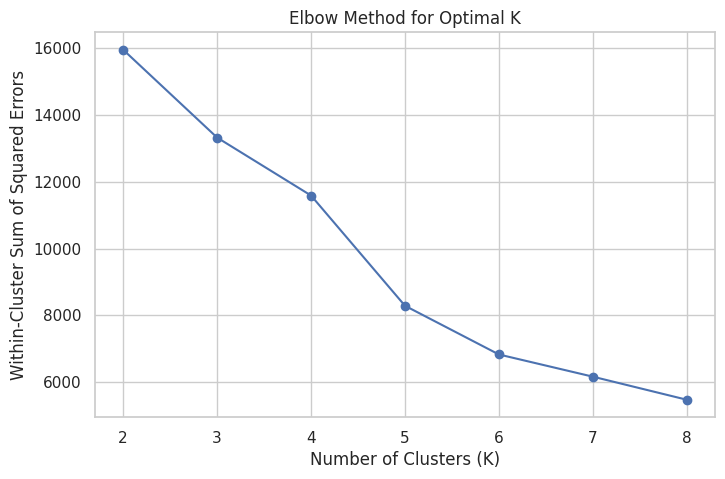

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(k_values, wssse_values, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squared Errors")
plt.title("Elbow Method for Optimal K")
plt.xticks(k_values)
plt.grid(True)
plt.show()

### 7.3 Training the Final K-Means Clustering Model

Based on the Elbow Method exploration, the final K-Means model is configured with five clusters (K=5). The model is trained using the standardized pollutant features and assigns each observation to one of the five clusters.

In [ ]:
from pyspark.ml.clustering import KMeans

# Train K-Means with 5 clusters
kmeans = KMeans(
    featuresCol="scaled_features",
    predictionCol="cluster",
    k=5,
    seed=42
)

kmeans_model = kmeans.fit(scaled_df)

# Generate cluster predictions
clustered_df = kmeans_model.transform(scaled_df)

print("K-MEANS MODEL TRAINED SUCCESSFULLY!")

# Display cluster assignments
clustered_df.select(
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "so2_rounded",
    "cluster"
).show(20, truncate=False)

K-MEANS MODEL TRAINED SUCCESSFULLY!
+-----------+----------+------------+-----------+-------+
|no2_rounded|o3_rounded|pm25_rounded|so2_rounded|cluster|
+-----------+----------+------------+-----------+-------+
|7.0        |20.2      |4.3         |0.2        |1      |
|18.2       |1.2       |6.5         |0.6        |2      |
|7.1        |11.3      |23.9        |0.3        |4      |
|8.2        |2.0       |7.3         |0.0        |2      |
|10.3       |17.4      |3.9         |0.6        |2      |
|1.1        |36.1      |1.2         |0.6        |1      |
|1.4        |19.5      |0.1         |0.2        |1      |
|1.8        |2.0       |27.6        |0.1        |4      |
|3.6        |1.6       |22.6        |0.1        |4      |
|1.3        |24.6      |1.9         |0.1        |1      |
|1.8        |24.8      |1.9         |0.1        |1      |
|3.9        |19.7      |5.1         |0.2        |1      |
|0.1        |28.3      |9.1         |0.3        |1      |
|6.1        |1.8       |10.6        

In [ ]:
from pyspark.sql import functions as F

# Count records in each cluster
cluster_counts = clustered_df.groupBy("cluster").count().orderBy("cluster")

print("NUMBER OF OBSERVATIONS IN EACH CLUSTER")

cluster_counts.show()

# Calculate percentage distribution
total_records = clustered_df.count()

cluster_counts.withColumn(
    "percentage",
    F.round((F.col("count") / total_records) * 100, 2)
).show()

NUMBER OF OBSERVATIONS IN EACH CLUSTER
+-------+-----+
|cluster|count|
+-------+-----+
|      0| 2210|
|      1| 1756|
|      2| 1150|
|      3|   41|
|      4|  263|
+-------+-----+

+-------+-----+----------+
|cluster|count|percentage|
+-------+-----+----------+
|      0| 2210|     40.77|
|      1| 1756|      32.4|
|      2| 1150|     21.22|
|      3|   41|      0.76|
|      4|  263|      4.85|
+-------+-----+----------+



### 7.4 Analyzing Pollutant Profiles Across Clusters

The average concentrations of NO2, O3, PM2.5, and SO2 are calculated for each cluster. These profiles help identify the pollutant characteristics that distinguish the five groups of observations.

In [ ]:
cluster_profiles = clustered_df.groupBy("cluster").agg(
    F.round(F.avg("no2_rounded"), 2).alias("Average_NO2"),
    F.round(F.avg("o3_rounded"), 2).alias("Average_O3"),
    F.round(F.avg("pm25_rounded"), 2).alias("Average_PM25"),
    F.round(F.avg("so2_rounded"), 2).alias("Average_SO2"),
    F.count("*").alias("Total_Records")
).orderBy("cluster")

print("POLLUTANT PROFILE OF EACH CLUSTER")

cluster_profiles.show(truncate=False)

POLLUTANT PROFILE OF EACH CLUSTER
+-------+-----------+----------+------------+-----------+-------------+
|cluster|Average_NO2|Average_O3|Average_PM25|Average_SO2|Total_Records|
+-------+-----------+----------+------------+-----------+-------------+
|0      |3.27       |7.56      |6.88        |0.4        |2210         |
|1      |2.61       |24.58     |4.05        |0.5        |1756         |
|2      |13.11      |5.86      |8.68        |0.46       |1150         |
|3      |6.65       |11.01     |15.7        |9.52       |41           |
|4      |6.66       |5.75      |28.24       |0.5        |263          |
+-------+-----------+----------+------------+-----------+-------------+



### 7.5 Visualizing Pollutant Patterns Across Clusters

A heatmap is used to compare standardized pollutant concentrations across the five clusters. This visualization makes it easier to identify which pollutants are relatively higher or lower within each group.

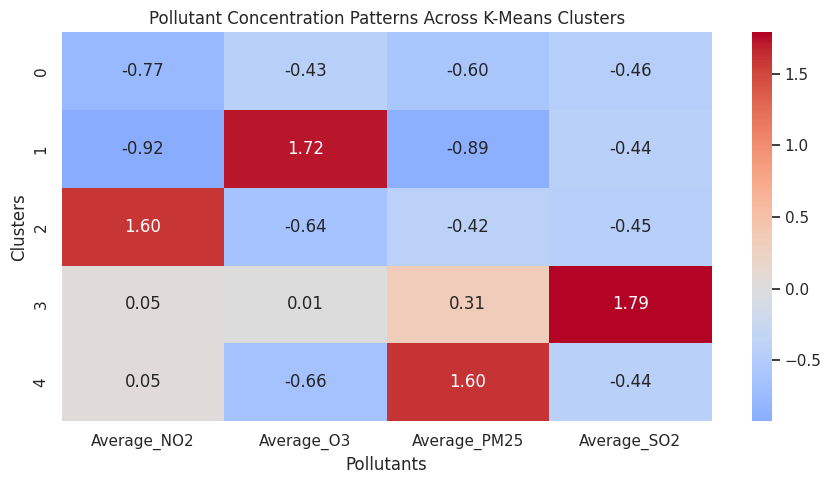

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert Spark cluster profiles to Pandas
profile_pd = cluster_profiles.toPandas()

# Select pollutant columns
pollutant_columns = [
    "Average_NO2",
    "Average_O3",
    "Average_PM25",
    "Average_SO2"
]

# Set cluster as index
heatmap_data = profile_pd.set_index("cluster")[pollutant_columns]

# Standardize columns for visualization
heatmap_normalized = (
    heatmap_data - heatmap_data.mean()
) / heatmap_data.std()

# Create heatmap
plt.figure(figsize=(9, 5))

sns.heatmap(
    heatmap_normalized,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Pollutant Concentration Patterns Across K-Means Clusters")
plt.xlabel("Pollutants")
plt.ylabel("Clusters")
plt.tight_layout()
plt.show()

### 7.6 Examining Cluster 3 and Its SO2 Concentrations

This section investigates Cluster 3, which was identified in the analysis as having relatively high SO2 observations. The pollutant readings and SO2 summary statistics are examined to understand this cluster's characteristics.

In [ ]:
# Examine observations belonging to Cluster 3

print("CLUSTER 3 - HIGH SO2 OBSERVATIONS")

clustered_df.filter(
    F.col("cluster") == 3
).select(
    "no2_rounded",
    "o3_rounded",
    "pm25_rounded",
    "so2_rounded"
).orderBy(
    F.col("so2_rounded").desc()
).show(50, truncate=False)

# Summary statistics for Cluster 3
clustered_df.filter(
    F.col("cluster") == 3
).select(
    F.min("so2_rounded").alias("Minimum_SO2"),
    F.max("so2_rounded").alias("Maximum_SO2"),
    F.avg("so2_rounded").alias("Average_SO2"),
    F.stddev("so2_rounded").alias("StdDev_SO2")
).show()

CLUSTER 3 - HIGH SO2 OBSERVATIONS
+-----------+----------+------------+-----------+
|no2_rounded|o3_rounded|pm25_rounded|so2_rounded|
+-----------+----------+------------+-----------+
|16.3       |7.0       |52.3        |31.7       |
|14.7       |9.8       |41.2        |29.7       |
|13.6       |5.4       |57.0        |24.7       |
|15.0       |10.3      |29.9        |23.9       |
|10.2       |16.9      |14.8        |13.7       |
|10.7       |13.7      |16.0        |11.9       |
|11.8       |3.3       |49.6        |11.9       |
|5.0        |15.8      |9.2         |11.4       |
|1.1        |6.6       |1.9         |10.1       |
|6.6        |8.8       |15.4        |9.8        |
|7.6        |7.3       |14.9        |9.0        |
|6.8        |26.4      |7.0         |8.6        |
|4.0        |5.7       |10.0        |8.4        |
|6.4        |5.5       |9.0         |8.3        |
|4.6        |4.3       |9.0         |8.1        |
|6.1        |10.3      |15.3        |7.9        |
|5.1        |16.

## 8. Overall Analysis Conclusion

This notebook explored air quality patterns in British Columbia using exploratory data analysis, data visualization, statistical analysis, supervised machine learning, and unsupervised learning.

The supervised learning experiments examined AQHI prediction through regression and next-hour risk classification.

For AQHI regression, Linear Regression achieved an R² score of 0.8035, while Random Forest Regression achieved an R² score of 0.8102. Random Forest performed slightly better in this experiment, with PM2.5 identified as the most influential feature.

The primary classification experiment used Random Forest to predict next-hour AQHI risk. The model achieved 96.51% accuracy, but its recall was only 10.14%, identifying 7 of the 69 elevated-risk observations in the test dataset. This demonstrates that high overall accuracy does not necessarily indicate strong performance when the dataset is imbalanced. The model requires further improvement before it could be considered reliable for practical risk forecasting.

The supplementary Logistic Regression experiment provided an additional classification comparison. K-Means clustering was also used to explore groups of observations based on NO2, O3, PM2.5, and SO2 concentrations. The cluster profiles helped identify differences in pollutant patterns, including a cluster with relatively high SO2 observations.

Overall, the experiments demonstrate how Big Data processing and machine learning techniques can be applied to air quality analysis. The findings also highlight the importance of data quality, class balance, feature selection, and appropriate evaluation metrics. Future improvements could include collecting a longer period of air quality observations, increasing the number of elevated-risk examples, and further tuning the prediction models.